# Part B: pretrained models, without training

Neither model sees a training example from this dataset. Every choice is made on val.

1. B1: NLI zero-shot for categories and polarity
2. B2: sentence sentiment copied on every aspect
3. Full pipeline on val

The text stays raw: these tokenizers were built for ordinary text (Q3).


**Running this notebook.** Each model has its own cell, and a finished run is saved on Drive. If a cell fails, rerun only that cell. After a lost session, run the notebook again: finished runs reload in seconds. To train one again, pass `retrain=True` in its cell.

## Setup

In [1]:
import os
import sys
from google.colab import drive
drive.mount("/content/drive")

REPO = "AR-aspect-sentiment"

if not os.path.exists(f"/content/{REPO}"):
    !git clone https://github.com/cad0m/{REPO}.git /content/{REPO}
else:
    !git -C /content/{REPO} pull

%cd /content/{REPO}

if f"/content/{REPO}" not in sys.path:
    sys.path.insert(0, f"/content/{REPO}")

!pip install -q arabert emoji gensim sentencepiece tashaphyne

OUTPUT_DIR = f"/content/drive/MyDrive/{REPO}"
os.environ["OUTPUT_DIR"] = OUTPUT_DIR
!mkdir -p {OUTPUT_DIR}

Mounted at /content/drive
Cloning into '/content/AR-aspect-sentiment'...
remote: Enumerating objects: 145, done.
remote: Counting objects: 100% (145/145), done.
remote: Compressing objects: 100% (98/98), done.
remote: Total 145 (delta 68), reused 106 (delta 42), pack-reused 0 (from 0)
Receiving objects: 100% (145/145), 9.21 MiB | 17.15 MiB/s, done.
Resolving deltas: 100% (68/68), done.
/content/AR-aspect-sentiment
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from tqdm.auto import tqdm
from transformers import AutoModelForSequenceClassification, AutoTokenizer

from src.aspect_names import hypothesis
from src.data import POLARITIES, category_list, category_matrix, load_test, load_train_val, pair_units, pairs
from src.evaluation import (
    THRESHOLD_GRID,
    accuracy_by_mixed_sentence,
    best_category_thresholds,
    best_global_threshold,
    category_report,
    category_scores,
    compare_threshold_policies,
    pairs_from_matrix,
    pipeline_outcomes,
    pipeline_scores,
    polarity_f1_by_class,
    polarity_scores,
    predict_labels,
)
from src.plots import (
    plot_category_f1,
    plot_f1_by_threshold,
    plot_grouped_bars,
    plot_mixed_accuracy,
    plot_model_comparison,
    plot_pipeline_outcomes,
    plot_polarity_confusion,
    plot_polarity_f1,
    plot_threshold_policies,
)
from src.tracking import best_of_each_model, cached_run, latency_ms, log_results, result_row, save_scores

SEED = 42
device = "cuda" if torch.cuda.is_available() else "cpu"
sns.set_theme(style="whitegrid", context="notebook")
print("Device:", device)

Device: cuda


In [3]:
opinions, train, val = load_train_val(SEED)

classes = category_list(opinions)
val_labels = category_matrix(val.categories, classes)
val_pairs = pairs(opinions, val)
val_units = pair_units(val_pairs)
clear_units = ~val_units.ambiguous.to_numpy(dtype=bool)

print(f"{len(val)} val sentences, {len(classes)} categories, {len(val_units)} (sentence, category) pairs")

481 val sentences, 34 categories, 930 (sentence, category) pairs


## 1. B1: NLI zero-shot

An NLI model reads a premise and a hypothesis and says if the first implies the second. The sentence is the premise, and "this sentence is about the service" is the hypothesis, so a category described in words needs no training example (Q4).

Like the Hugging Face zero-shot pipeline in multi-label mode, the score of a hypothesis is the softmax over entailment and contradiction.

In [4]:
NLI_NAME = "MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7"

nli_tokenizer = AutoTokenizer.from_pretrained(NLI_NAME)
nli_model = AutoModelForSequenceClassification.from_pretrained(NLI_NAME).to(device).eval()
label_ids = nli_model.config.label2id
entailment_and_contradiction = [label_ids["entailment"], label_ids["contradiction"]]


def entailment_scores(premises, hypotheses, batch_size=128):
    scores = []
    for start in tqdm(range(0, len(premises), batch_size), desc="entailment", leave=False):
        batch = nli_tokenizer(
            premises[start:start + batch_size], hypotheses[start:start + batch_size],
            truncation=True, max_length=128, padding=True, return_tensors="pt",
        ).to(device)
        with torch.inference_mode():
            logits = nli_model(**batch).logits
        scores.append(logits[:, entailment_and_contradiction].softmax(dim=1)[:, 0].cpu().numpy())
    return np.concatenate(scores)

config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/467 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 4.31MB            

spm.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 16.3MB            

...

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

### Categories: one formulation per language, each with its own threshold

In [5]:
def category_entailment(sentence_table, language, template):
    hypotheses = [hypothesis(template, category, language) for category in classes]
    premises = [text for text in sentence_table.text for _ in classes]
    return entailment_scores(premises, hypotheses * len(sentence_table)).reshape(len(sentence_table), len(classes))


def run_category_hypothesis(language, template, retrain=False):
    print(hypothesis(template, "SERVICE#GENERAL", language))
    scores = cached_run(f"nli_category_{language}", lambda: category_entailment(val, language, template), retrain)
    threshold, _ = best_global_threshold(scores, val_labels)
    result = category_scores(val_labels, predict_labels(scores, threshold))
    log_results([result_row("category", "nli zero-shot", "raw", f"hypothesis={language}", "global", **result)])
    print(f"threshold {threshold:.2f}, micro-F1 {result['micro_f1']:.4f}, macro-F1 {result['macro_f1']:.4f}")
    return {"name": language, "template": template, "scores": scores, **result}

In [6]:
arabic_categories = run_category_hypothesis("arabic", "هذه الجملة تتحدث عن {aspect}.")

هذه الجملة تتحدث عن خدمة الفندق بشكل عام.
nli_category_arabic: loaded from disk
threshold 0.74, micro-F1 0.2214, macro-F1 0.2062


/content/AR-aspect-sentiment/src/tracking.py:55: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  table = pd.concat([pd.read_csv(path), table], ignore_index=True)


In [7]:
french_categories = run_category_hypothesis("french", "Cette phrase parle de {aspect}.")

Cette phrase parle du service de l'hôtel en général.
nli_category_french: loaded from disk
threshold 0.54, micro-F1 0.2470, macro-F1 0.1949


/content/AR-aspect-sentiment/src/tracking.py:55: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  table = pd.concat([pd.read_csv(path), table], ignore_index=True)


In [8]:
english_categories = run_category_hypothesis("english", "This sentence is about {aspect}.")

This sentence is about the hotel service in general.
nli_category_english: loaded from disk
threshold 0.56, micro-F1 0.2639, macro-F1 0.2086


/content/AR-aspect-sentiment/src/tracking.py:55: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  table = pd.concat([pd.read_csv(path), table], ignore_index=True)


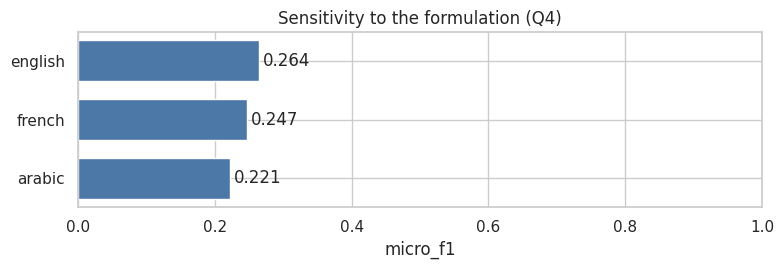

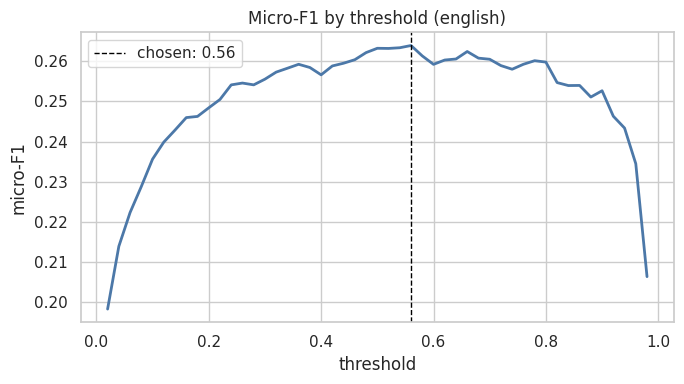

In [9]:
category_runs = pd.DataFrame([arabic_categories, french_categories, english_categories])
plot_model_comparison(category_runs, "micro_f1", title="Sensitivity to the formulation (Q4)")

best_run = category_runs.sort_values("micro_f1", ascending=False).iloc[0]
val_scores = best_run["scores"]
global_threshold, f1_curve = best_global_threshold(val_scores, val_labels)
plot_f1_by_threshold(THRESHOLD_GRID, f1_curve, global_threshold, title=f"Micro-F1 by threshold ({best_run['name']})")

Global or per-category threshold, tuned on half of the val reviews and scored on the other half:

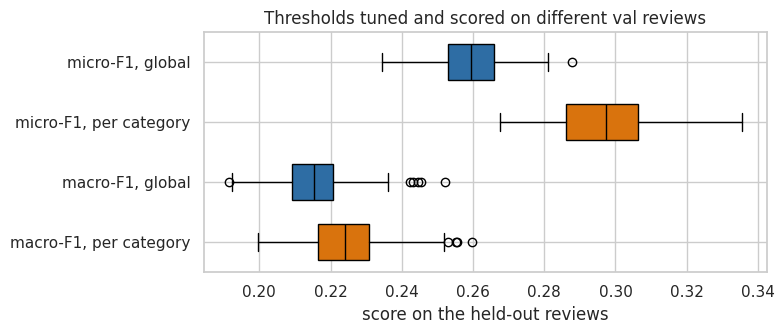

/content/AR-aspect-sentiment/src/tracking.py:55: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  table = pd.concat([pd.read_csv(path), table], ignore_index=True)


per_category {'micro_f1': 0.31802721088435376, 'macro_f1': 0.25960425155069417, 'precision': 0.21593533487297922, 'recall': 0.603225806451613}


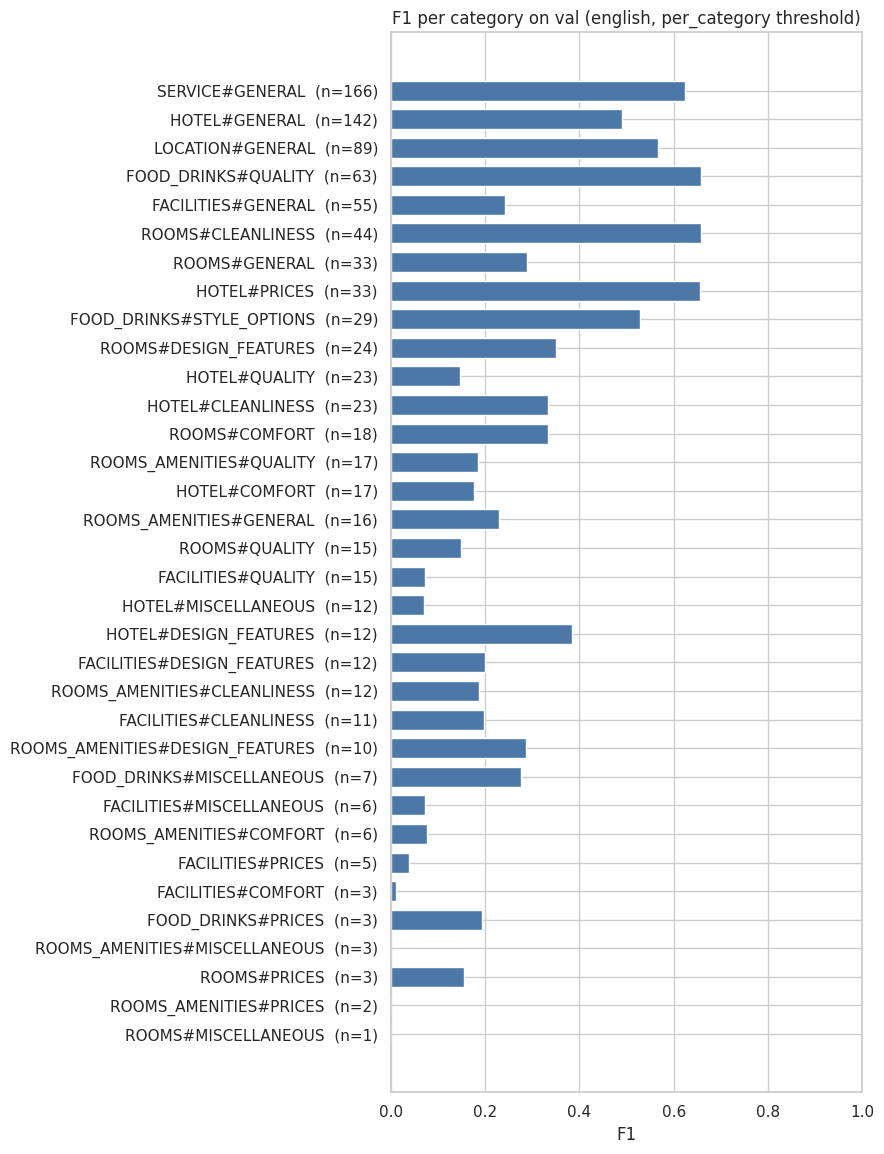

In [10]:
holdout = compare_threshold_policies(val_scores, val_labels, val.review_id, seed=SEED)
plot_threshold_policies(holdout)

use_per_category = holdout.micro_f1_per_category.mean() > holdout.micro_f1_global.mean()
threshold_policy = "per_category" if use_per_category else "global"
chosen_thresholds = best_category_thresholds(val_scores, val_labels, global_threshold) if use_per_category else global_threshold

val_predictions = predict_labels(val_scores, chosen_thresholds)
category_result = category_scores(val_labels, val_predictions)
log_results([result_row("category", "nli zero-shot", "raw", f"hypothesis={best_run['name']}", threshold_policy, **category_result)])
print(threshold_policy, category_result)
plot_category_f1(category_report(val_labels, val_predictions, classes), title=f"F1 per category on val ({best_run['name']}, {threshold_policy} threshold)")

**Conclusions (Q4)**

_To fill in after the run: best formulation and score, gap between languages, comparison with TF-IDF + LR._

### Polarity

Each pair gets one hypothesis per polarity, and the highest entailment wins. The category is given, so this measures polarity alone.

In [11]:
POLARITY_WORDS = {
    "arabic": {"negative": "سلبي", "neutral": "محايد", "positive": "إيجابي"},
    "french": {"negative": "négatif", "neutral": "neutre", "positive": "positif"},
    "english": {"negative": "negative", "neutral": "neutral", "positive": "positive"},
}


def polarity_entailment(pair_table, language, template):
    """One row per pair, one column per polarity."""
    premises = [text for text in pair_table.text for _ in POLARITIES]
    hypotheses = [
        hypothesis(template, category, language, POLARITY_WORDS[language][polarity])
        for category in pair_table.category for polarity in POLARITIES
    ]
    return entailment_scores(premises, hypotheses).reshape(len(pair_table), len(POLARITIES))


def top_polarity(scores):
    return np.array(POLARITIES, dtype=object)[scores.argmax(axis=1)]


def run_polarity_hypothesis(language, template, retrain=False):
    scores = cached_run(f"nli_polarity_{language}", lambda: polarity_entailment(val_units, language, template), retrain)
    result = polarity_scores(val_units, top_polarity(scores))
    log_results([result_row("polarity", "nli zero-shot", "raw", f"hypothesis={language}", **result)])
    print(result)
    return {"name": language, "template": template, "scores": scores, **result}

In [12]:
arabic_polarity = run_polarity_hypothesis("arabic", "الرأي في {aspect} {polarity}.")

nli_polarity_arabic: loaded from disk
{'accuracy': 0.8512486427795874, 'macro_f1': 0.6053227420026173}


/content/AR-aspect-sentiment/src/tracking.py:55: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  table = pd.concat([pd.read_csv(path), table], ignore_index=True)


In [13]:
french_polarity = run_polarity_hypothesis("french", "L'avis sur {aspect} est {polarity}.")

nli_polarity_french: loaded from disk
{'accuracy': 0.8631921824104235, 'macro_f1': 0.593858558990683}


/content/AR-aspect-sentiment/src/tracking.py:55: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  table = pd.concat([pd.read_csv(path), table], ignore_index=True)


In [14]:
english_polarity = run_polarity_hypothesis("english", "The opinion about {aspect} is {polarity}.")

nli_polarity_english: loaded from disk
{'accuracy': 0.8555917480998915, 'macro_f1': 0.5900534103843796}


/content/AR-aspect-sentiment/src/tracking.py:55: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  table = pd.concat([pd.read_csv(path), table], ignore_index=True)


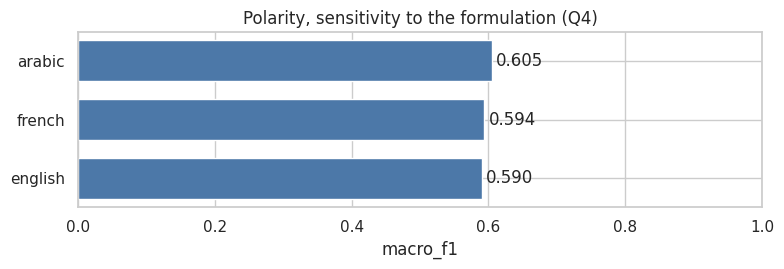

In [15]:
polarity_runs = pd.DataFrame([arabic_polarity, french_polarity, english_polarity])
plot_model_comparison(polarity_runs, "macro_f1", title="Polarity, sensitivity to the formulation (Q4)")

best_polarity_run = polarity_runs.sort_values("macro_f1", ascending=False).iloc[0]
nli_polarities = top_polarity(best_polarity_run["scores"])

## 2. B2: sentence sentiment copied on every aspect

One polarity per sentence, given to all its aspects. The model knows nothing about aspects.

In [16]:
SENTIMENT_NAME = "CAMeL-Lab/bert-base-arabic-camelbert-da-sentiment"

sentiment_tokenizer = AutoTokenizer.from_pretrained(SENTIMENT_NAME)
sentiment_model = AutoModelForSequenceClassification.from_pretrained(SENTIMENT_NAME).to(device).eval()
polarity_columns = [sentiment_model.config.label2id[polarity] for polarity in POLARITIES]


def sentence_sentiment(texts, batch_size=64):
    """One row per sentence, one column per polarity."""
    probabilities = []
    for start in tqdm(range(0, len(texts), batch_size), desc="sentiment", leave=False):
        batch = sentiment_tokenizer(
            texts[start:start + batch_size], truncation=True, max_length=128, padding=True, return_tensors="pt",
        ).to(device)
        with torch.inference_mode():
            probabilities.append(sentiment_model(**batch).logits.softmax(dim=1)[:, polarity_columns].cpu().numpy())
    return np.concatenate(probabilities)

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/86.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/305k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  436MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [17]:
sentiment_probabilities = cached_run("camelbert_sentiment_val", lambda: sentence_sentiment(val.text.tolist()))
sentence_polarity = pd.Series(top_polarity(sentiment_probabilities), index=val.sentence_id)

copied_polarities = val_units.sentence_id.map(sentence_polarity).to_numpy(dtype=object)
sentiment_result = polarity_scores(val_units, copied_polarities)
log_results([result_row("polarity", "camelbert sentiment copied", "raw", **sentiment_result)])
sentiment_result

camelbert_sentiment_val: loaded from disk


model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

/content/AR-aspect-sentiment/src/tracking.py:55: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  table = pd.concat([pd.read_csv(path), table], ignore_index=True)


{'accuracy': 0.742671009771987, 'macro_f1': 0.5537851985827654}

### Where it fails (Q5)

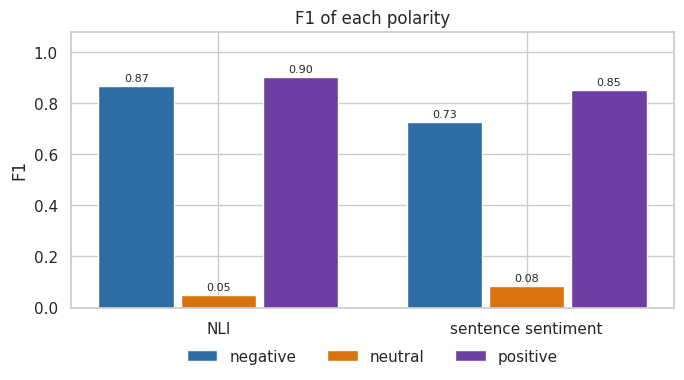

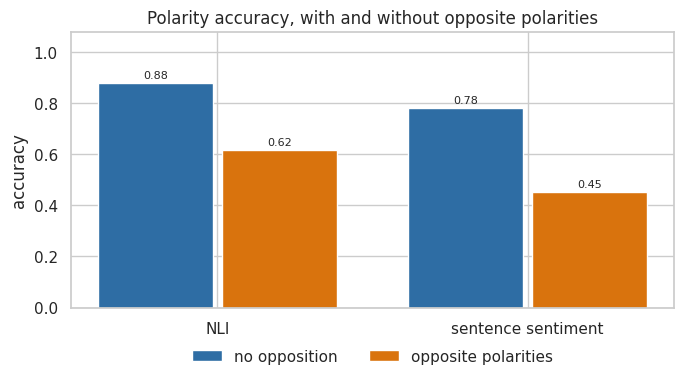

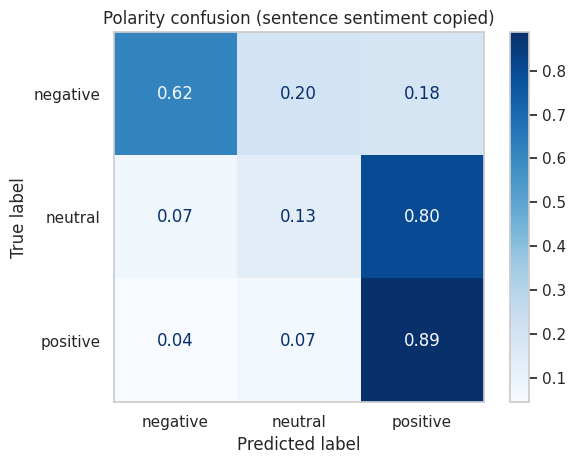

In [18]:
plot_polarity_f1({
    "NLI": polarity_f1_by_class(val_units, nli_polarities),
    "sentence sentiment": polarity_f1_by_class(val_units, copied_polarities),
})
plot_mixed_accuracy({
    "NLI": accuracy_by_mixed_sentence(val_units, nli_polarities),
    "sentence sentiment": accuracy_by_mixed_sentence(val_units, copied_polarities),
})
plot_polarity_confusion(val_units.polarity[clear_units], copied_polarities[clear_units], title="Polarity confusion (sentence sentiment copied)")

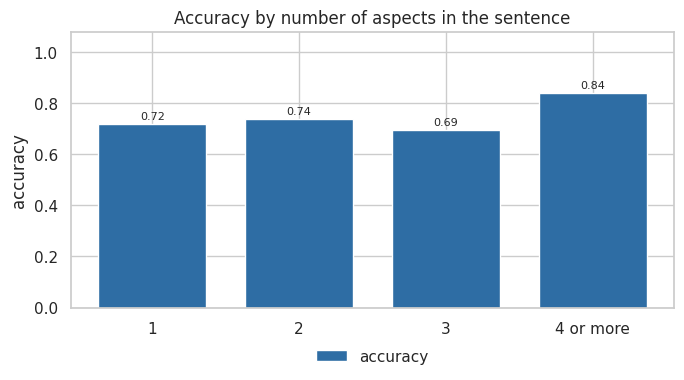

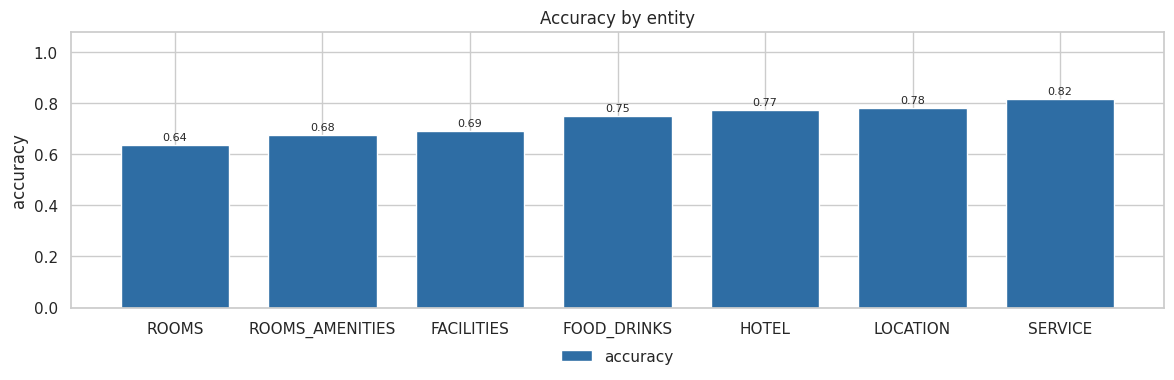

,category,polarity,predicted,text
0,SERVICE#GENERAL,positive,negative,(وهم يرشون المكان طوال الوقت ولكن الصراصير لا ...
1,FACILITIES#QUALITY,negative,positive,على كل حال فندق جميل وخدمه رائعة ولكن الانترني...
2,FOOD_DRINKS#QUALITY,neutral,positive,ترتيب جيد لتوقف عابر استخدمت هذا الفندق كإقامة...
3,LOCATION#GENERAL,neutral,positive,ترتيب جيد لتوقف عابر استخدمت هذا الفندق كإقامة...
4,SERVICE#GENERAL,neutral,positive,فيه حمام سباحة جميل مع بار صغير ومطعم ذو بوفيه...
5,HOTEL#GENERAL,neutral,positive,فندق جيد جدا من خلال تجربتي فهذا الفندق ارى ان...
6,ROOMS#DESIGN_FEATURES,negative,positive,فندق جيد جدا من خلال تجربتي فهذا الفندق ارى ان...
7,SERVICE#GENERAL,negative,neutral,موظفة الاستقبال غير محترفة لم يكن الفندق سيئاً...


In [19]:
aspects_per_sentence = val_units.groupby("sentence_id").category.transform("size")
failure_check = val_units[clear_units].assign(
    predicted=copied_polarities[clear_units],
    correct=lambda table: table.predicted == table.polarity,
    aspects_in_sentence=aspects_per_sentence[clear_units].clip(upper=4).astype(str).replace("4", "4 or more"),
    entity=lambda table: table.category.str.split("#").str[0],
)

plot_grouped_bars(failure_check.groupby("aspects_in_sentence").correct.mean().to_frame("accuracy"), "accuracy", "Accuracy by number of aspects in the sentence")
plot_grouped_bars(failure_check.groupby("entity").correct.mean().sort_values().to_frame("accuracy"), "accuracy", "Accuracy by entity")

mixed_sentences = failure_check.groupby("sentence_id").polarity.transform("nunique") > 1
failure_check[mixed_sentences & ~failure_check.correct][["category", "polarity", "predicted", "text"]].head(8).reset_index(drop=True)

**Conclusions (Q5)**

_To fill in after the run: score against the gold sentence rule of Part A (macro-F1 0.846), accuracy on mixed sentences and on `neutral`._

## 3. Full pipeline on val

The categories come from B1, and the polarity from B1 or B2.

2598 predicted pairs for 1075 gold opinions
nli_pipeline_polarity_val: loaded from disk


/content/AR-aspect-sentiment/src/tracking.py:55: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  table = pd.concat([pd.read_csv(path), table], ignore_index=True)


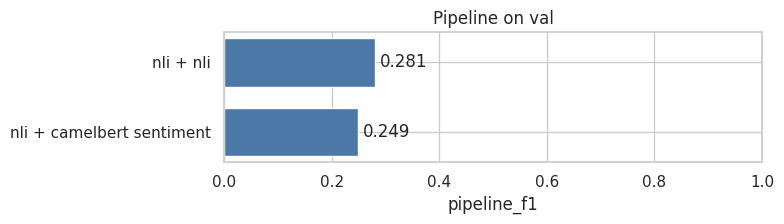

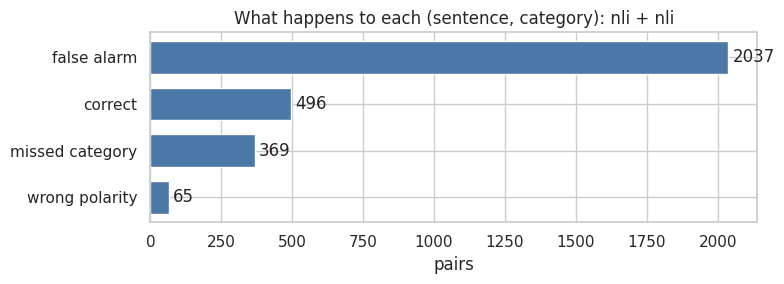

In [20]:
predicted_pairs = pairs_from_matrix(val, val_predictions, classes)
print(f"{len(predicted_pairs)} predicted pairs for {len(val_pairs)} gold opinions")

pair_scores = cached_run(
    "nli_pipeline_polarity_val",
    lambda: polarity_entailment(predicted_pairs, best_polarity_run["name"], best_polarity_run["template"]),
)
nli_outcomes = pipeline_outcomes(val_pairs, predicted_pairs.assign(polarity=top_polarity(pair_scores)))
sentiment_outcomes = pipeline_outcomes(val_pairs, predicted_pairs.assign(polarity=predicted_pairs.sentence_id.map(sentence_polarity)))

pipeline_results = pd.DataFrame([
    {"name": "nli + nli", **pipeline_scores(nli_outcomes)},
    {"name": "nli + camelbert sentiment", **pipeline_scores(sentiment_outcomes)},
])
results = log_results([
    result_row("pipeline", row.name, "raw", threshold_policy=threshold_policy, micro_f1=row.pipeline_f1)
    for row in pipeline_results.itertuples()
])
plot_model_comparison(pipeline_results, "pipeline_f1", title="Pipeline on val")
plot_pipeline_outcomes(nli_outcomes, title="What happens to each (sentence, category): nli + nli")

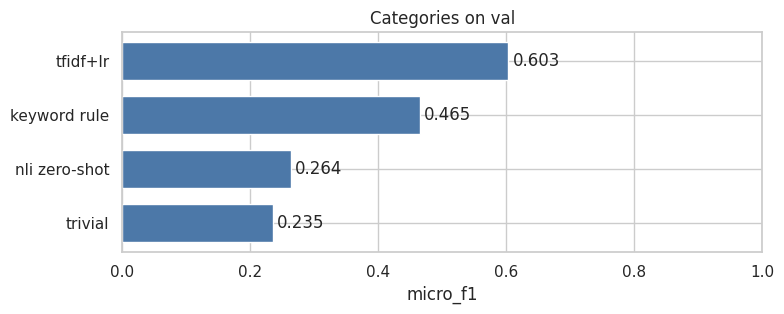

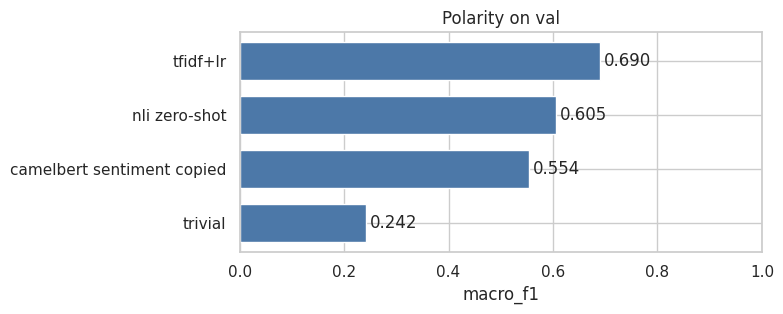

In [21]:
plot_model_comparison(best_of_each_model(results, "category", "micro_f1"), "micro_f1", title="Categories on val")
plot_model_comparison(best_of_each_model(results, "polarity", "macro_f1"), "macro_f1", title="Polarity on val")

**Conclusions**

_To fill in after the run: zero-shot against the keyword rule and TF-IDF + LR, and which polarity source the pipeline prefers._

## 4. Save the val scores

In [22]:
thresholds_to_save = np.broadcast_to(chosen_thresholds, len(classes)).tolist()
save_scores("zero_shot_category", "val", val_scores, {"sentence_id": val.sentence_id.to_numpy()}, classes,
            meta={"language": best_run["name"], "threshold_policy": threshold_policy, "thresholds": thresholds_to_save})

## 5. Test predictions for Part F


Run this section only when the choices above are final. It writes the predictions on the test set for `06_final_test` and prints no score, so nothing here can influence a choice.

In [23]:
test_opinions, test = load_test()
test_units = pair_units(pairs(test_opinions, test))
sentence_ids = {"sentence_id": test.sentence_id.to_numpy()}
pair_ids = {"sentence_id": test_units.sentence_id.to_numpy(), "category": test_units.category.to_numpy()}

test_scores = cached_run("nli_category_test", lambda: category_entailment(test, best_run["name"], best_run["template"]))
test_predictions = predict_labels(test_scores, chosen_thresholds)

nli_category_test: loaded from disk


In [24]:
test_polarity_scores = cached_run("nli_polarity_test", lambda: polarity_entailment(test_units, best_polarity_run["name"], best_polarity_run["template"]))
save_scores("zero_shot_polarity", "test", [test_polarity_scores], pair_ids, POLARITIES)

test_pairs = pairs_from_matrix(test, test_predictions, classes)
test_pipeline_scores = cached_run("nli_pipeline_polarity_test", lambda: polarity_entailment(test_pairs, best_polarity_run["name"], best_polarity_run["template"]))
save_scores("zero_shot_pipeline", "test", [test_pipeline_scores],
            {"sentence_id": test_pairs.sentence_id.to_numpy(), "category": test_pairs.category.to_numpy()}, POLARITIES)

nli_polarity_test: loaded from disk
nli_pipeline_polarity_test: loaded from disk


In [25]:
test_sentiment = cached_run("camelbert_sentiment_test", lambda: sentence_sentiment(test.text.tolist()))
row_of_sentence = dict(zip(test.sentence_id, range(len(test))))
save_scores("camelbert_sentiment_polarity", "test", [test_sentiment[test_units.sentence_id.map(row_of_sentence).to_numpy()]], pair_ids, POLARITIES)

camelbert_sentiment_test: loaded from disk


CPU latency of one sentence, which means one hypothesis per category:

In [26]:
SECONDS_PER_PAIR_ON_CPU = 6.47

save_scores("zero_shot_category", "test", [test_scores], sentence_ids, classes, meta={
    "thresholds": thresholds_to_save,
    "train_s": 0.0,
    "latency_ms": SECONDS_PER_PAIR_ON_CPU * len(classes) * 1000,
    "size_mb": sum(parameter.numel() for parameter in nli_model.parameters()) * 4 / 1e6,
})
print("Test scores saved")

Test scores saved
